In [28]:
import pandas as pd


# Load Dataset
df=pd.read_csv("retail_sales_dataset.csv")

In [30]:
# Shape
df.shape

(1000, 9)

In [3]:
print(df.dtypes)

Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object


In [37]:
df.head(10)

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
5,6,2023-04-25,CUST006,Female,45,Beauty,1,30,30
6,7,2023-03-13,CUST007,Male,46,Clothing,2,25,50
7,8,2023-02-22,CUST008,Male,30,Electronics,4,25,100
8,9,2023-12-13,CUST009,Male,63,Electronics,2,300,600
9,10,2023-10-07,CUST010,Female,52,Clothing,4,50,200


In [5]:
# Null value check
print(df.isnull().sum())

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [6]:
# mean

df.mean(numeric_only=True)

Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

In [7]:
# median

df.median(numeric_only=True)

Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

In [8]:
df.mode(numeric_only=True).iloc[0]

Transaction ID     1.0
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

In [9]:
df.std(numeric_only=True)

Transaction ID    288.819436
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64

In [10]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [11]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')

### Time series analysis

In [12]:
print(df['Date'])

0      2023-11-24
1      2023-02-27
2      2023-01-13
3      2023-05-21
4      2023-05-06
          ...    
995    2023-05-16
996    2023-11-17
997    2023-10-29
998    2023-12-05
999    2023-04-12
Name: Date, Length: 1000, dtype: str


In [13]:
df['Date']=pd.to_datetime(df['Date'])

### Monthly

In [14]:
monthly_sales=df.set_index('Date')['Total Amount'].resample('MS').sum()
monthly_sales

Date
2023-01-01    35450
2023-02-01    44060
2023-03-01    28990
2023-04-01    33870
2023-05-01    53150
2023-06-01    36715
2023-07-01    35465
2023-08-01    36960
2023-09-01    23620
2023-10-01    46580
2023-11-01    34920
2023-12-01    44690
2024-01-01     1530
Freq: MS, Name: Total Amount, dtype: int64

Import Seaborn Library

In [15]:
%pip install seaborn

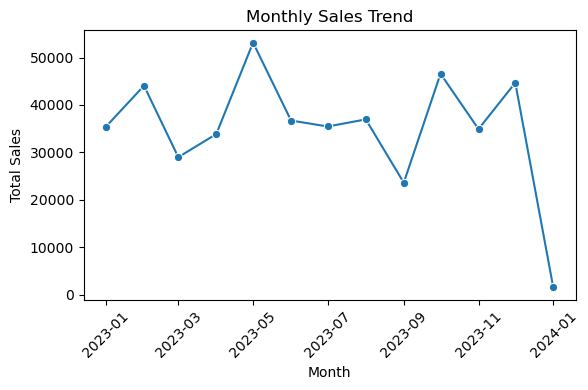

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))
sns.lineplot(x=monthly_sales.index,y=monthly_sales.values,marker='o')
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Quarterly Sales Trend

In [17]:
quarterly_sales=df.set_index('Date')['Total Amount'].resample('QS').sum()
quarterly_sales

Date
2023-01-01    108500
2023-04-01    123735
2023-07-01     96045
2023-10-01    126190
2024-01-01      1530
Freq: QS-JAN, Name: Total Amount, dtype: int64

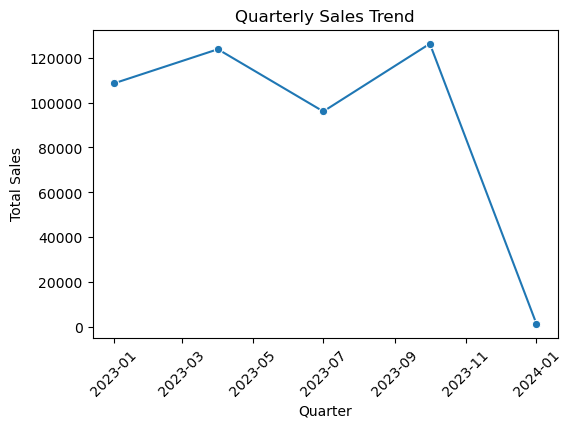

In [18]:
plt.figure(figsize=(6,4))
sns.lineplot(x=quarterly_sales.index,y=quarterly_sales.values,marker='o')
plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

 ### Customer demographics analysis

In [19]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')

In [20]:
df['Age'].describe()

count    1000.00000
mean       41.39200
std        13.68143
min        18.00000
25%        29.00000
50%        42.00000
75%        53.00000
max        64.00000
Name: Age, dtype: float64

In [60]:
bins=[0, 11, 18, 25, 45, 59, 100]
labels=['Child','Teenager','Young Adult','Adult','Middle-Aged','Senior']
df['age_group']=pd.cut(df['Age'],bins=bins,labels=labels)

In [61]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount',
       'age_group'],
      dtype='str')

In [23]:
cols = ["Age", "age_group"]
print(df[cols])

     Age    age_group
0     34        Adult
1     26        Adult
2     50  Middle-Aged
3     37        Adult
4     30        Adult
..   ...          ...
995   62       Senior
996   52  Middle-Aged
997   23  Young Adult
998   36        Adult
999   47  Middle-Aged

[1000 rows x 2 columns]


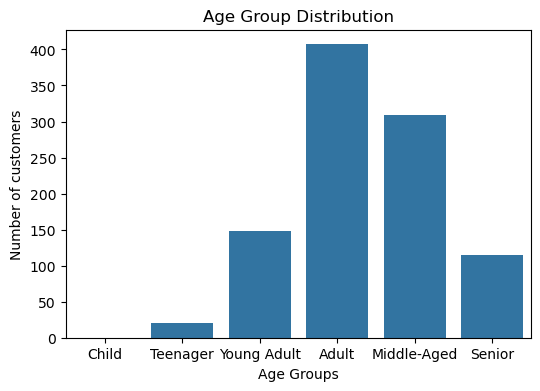

In [24]:
plt.figure(figsize=(6,4))

sns.countplot(data=df,x='age_group')
plt.title("Age Group Distribution")
plt.xlabel("Age Groups")
plt.ylabel("Number of customers")
plt.show()


### Gender breakdown

In [25]:
df['Gender'].value_counts()

Gender
Female    510
Male      490
Name: count, dtype: int64

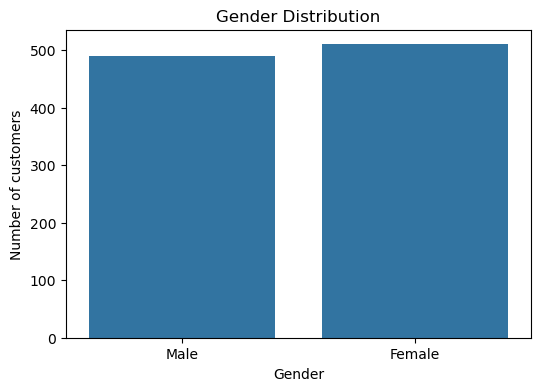

In [26]:
plt.figure(figsize=(6,4))

sns.countplot(data=df,x='Gender')
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of customers")
plt.show()

In [27]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount',
       'age_group'],
      dtype='str')

In [34]:
top_products=df['Product Category'].value_counts()
top_products

Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64

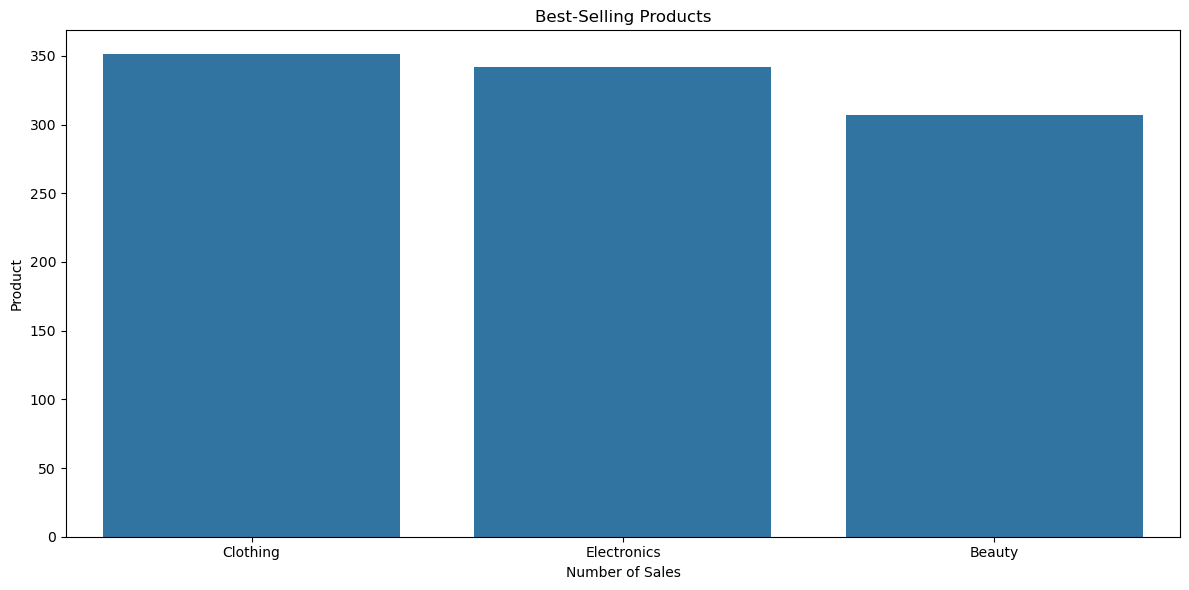

In [38]:
plt.figure(figsize=(12, 6))

sns.barplot( x=top_products.index,y=top_products.values)

plt.title("Best-Selling Products")
plt.xlabel("Number of Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [41]:
category_revenue=df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False)
category_revenue

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

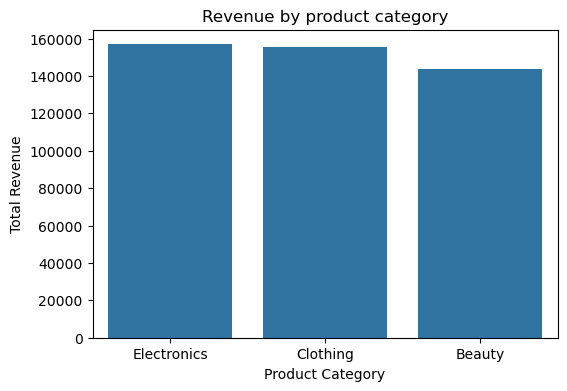

In [43]:
plt.figure(figsize=(6,4))
sns.barplot(x=category_revenue.index,y=category_revenue.values)

plt.title("Revenue by product category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.show()

In [46]:
numeric_col=df.select_dtypes(include="number")
numeric_col.columns

Index(['Transaction ID', 'Age', 'Quantity', 'Price per Unit', 'Total Amount'], dtype='str')

In [47]:
correlation_matrix = numeric_col.corr()
correlation_matrix

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
Transaction ID,1.000000,0.065191,-0.026623,-0.060837,-0.075034
Age,0.065191,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.026623,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.060837,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.075034,-0.060568,0.373707,0.851925,1.000000


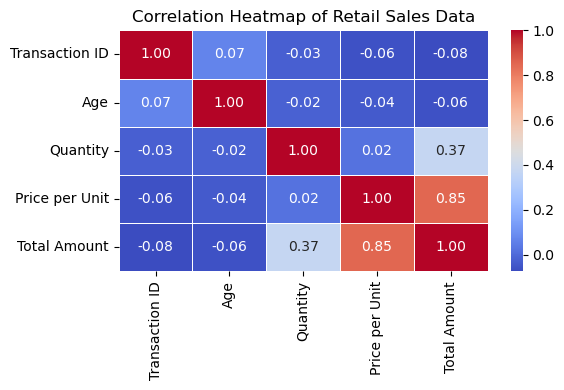

In [53]:
plt.figure(figsize=(6,4))
sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm",
    fmt=".2f",linewidths=0.5)

plt.title("Correlation Heatmap of Retail Sales Data")
plt.tight_layout()
plt.show()

In [62]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount',
       'age_group'],
      dtype='str')

In [65]:
average_spending=df.groupby("age_group")['Total Amount'].mean()
average_spending

age_group
Teenager       534.047619
Young Adult    495.506757
Adult          467.690418
Middle-Aged    441.051780
Senior         389.695652
Name: Total Amount, dtype: float64

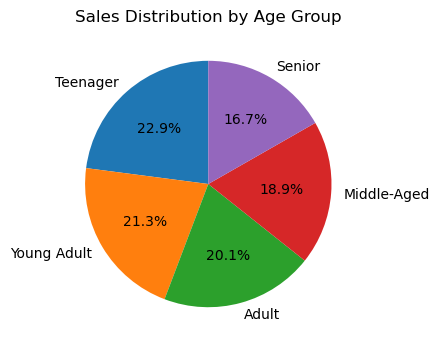

In [67]:
plt.figure(figsize=(6,4))
plt.pie(average_spending,labels=average_spending.index,autopct="%1.1f%%",
    startangle=90)
plt.title("Sales Distribution by Age Group")
plt.show()